In [1]:
import numpy as np
from astropy.io import fits
import glob 
import matplotlib.pyplot as plt
from pathlib import Path
import os

In [2]:
def f_master_bias(cube_files):
    """
    Create a master bias from one or several cubes of zero-exposure frames.
    Each cube is shifted to a common pedestal (it drifts by a few 0.1 ADU during the night),
    then the frames are combined with a 3-sigma clipped mean, which is less noisy than the
    median and still rejects cosmic rays.
    The result is exposure-time independent (bias is read noise only).
    """
    if isinstance(cube_files, str):
        cube_files = [cube_files]

    cubes = [fits.getdata(f).astype(np.float32) for f in cube_files]
    pedestal = np.median(cubes[0])
    data_cube = np.concatenate([cube - (np.median(cube) - pedestal) for cube in cubes], axis=0)
    print(f"Combining {data_cube.shape[0]} zero-exposure frames")

    median = np.median(data_cube, axis=0)
    rms = 1.4826 * np.median(np.abs(data_cube - median), axis=0)
    rms[rms == 0] = 1  # integer data: a constant pixel has MAD 0
    good = np.abs(data_cube - median) <= 3 * rms
    master_bias = np.sum(data_cube * good, axis=0) / np.sum(good, axis=0)
    return master_bias.astype(np.float64)


def f_master_dark(dark_cube_file, master_bias_file):
    """
    Create a master dark current rate frame [ADU/s].
    Bias is subtracted, then frames are median-combined, then divided by
    exposure time → result is exposure-time independent (ADU per second).
    Apply to science frames as: master_dark * science_exposure_time
    """
    with fits.open(dark_cube_file) as hdul:
        dark_cube = hdul[0].data.astype(float)
        dark_exposure = hdul[0].header['EXPTIME']
        print(f"Dark exposure time: {dark_exposure} seconds")

    master_bias = fits.getdata(master_bias_file).astype(float)

    # FIX: subtract 2D master_bias from each frame in the 3D cube via broadcasting,
    # median-combine across frames, THEN divide by exposure time.
    # Previously the subtraction and division order was wrong for broadcasting.
    dark_bias_corrected = dark_cube - master_bias[np.newaxis, :, :]
    master_dark = np.median(dark_bias_corrected, axis=0) / dark_exposure

    return master_dark  # units: ADU/s


def f_master_flat(flat_cube_file, master_bias_file, master_dark_file):
    """
    Create a normalized master flat field.
    Bias and scaled dark current are removed, frames are median-combined,
    then normalized to a median of 1.0. Vignetted pixels are set to NaN.
    """
    with fits.open(flat_cube_file) as hdul:
        flat_cube = hdul[0].data.astype(float)
        flat_exposure = hdul[0].header["EXPTIME"]
        print(f"Flat exposure time: {flat_exposure} seconds")

    master_bias = fits.getdata(master_bias_file).astype(float)
    master_dark = fits.getdata(master_dark_file).astype(float)

    # FIX: broadcast 2D calibration frames against the 3D cube correctly.
    # Previously master_bias was subtracted from the cube directly (broadcasting
    # issue), and the dark scaling happened before the median (also wrong order).
    flat_bias_corrected = flat_cube - master_bias[np.newaxis, :, :]
    flat_dark_corrected = flat_bias_corrected - master_dark[np.newaxis, :, :] * flat_exposure

    # FIX: the twilight sky faded from 37000 to 22000 ADU during the flat sequence, so each frame
    # has to be scaled to its own level before the median, otherwise the bright frames dominate.
    frame_levels = np.median(flat_dark_corrected, axis=(1, 2))
    print("Flat frame levels:", np.round(frame_levels))
    master_flat_raw = np.median(flat_dark_corrected / frame_levels[:, np.newaxis, np.newaxis], axis=0)
    master_flat = master_flat_raw / np.median(master_flat_raw)

    # Mask vignetted pixels (< 50% of median response)
    vignette_threshold = 0.5
    master_flat[master_flat < vignette_threshold] = np.nan

    return master_flat  # normalized, dimensionless; NaN where vignetted


def f_bad_pixel_mask(master_dark_file, master_flat_file, max_dark_rate=10.0, flat_range=(0.5, 1.5)):
    """
    True for pixels that cannot be calibrated: very hot pixels [ADU/s] and pixels with an
    implausible flat response. The vignetted corners are NaN in the flat and are also True.
    """
    master_dark = fits.getdata(master_dark_file).astype(float)
    master_flat = fits.getdata(master_flat_file).astype(float)
    with np.errstate(invalid='ignore'):
        return (np.abs(master_dark) > max_dark_rate) | ~(master_flat > flat_range[0]) | ~(master_flat < flat_range[1])


def f_science_frame(raw_science_file, master_bias_file, master_dark_file, master_flat_file, bad_pixel_mask=None):
    """
    Reduce a raw science frame:
        reduced = (raw - bias - dark_rate * t_exp) / flat
    Works for any exposure time because master_dark is in ADU/s.
    """
    with fits.open(raw_science_file) as hdul:
        raw_science_data = hdul[0].data.astype(float)
        science_header = hdul[0].header
        science_exposure = science_header['EXPTIME']
        print(f"Science exposure time: {science_exposure} seconds")

    master_bias = fits.getdata(master_bias_file).astype(float)
    master_dark = fits.getdata(master_dark_file).astype(float)
    master_flat = fits.getdata(master_flat_file).astype(float)

    # FIX: removed unused dark_cube_file parameter that was carried over by mistake.
    # FIX: handle both zeros AND NaNs (from vignette mask) in master_flat,
    # so they don't silently corrupt science pixels — set reduced value to NaN instead.
    bias_dark_corrected = raw_science_data - master_bias - master_dark * science_exposure

    # Replace 0 and NaN flat pixels with NaN → bad pixels stay NaN in output
    flat_safe = master_flat.copy()
    flat_safe[flat_safe == 0] = np.nan  # was 1e-10 before, which hid bad pixels

    science_frame = bias_dark_corrected / flat_safe

    if bad_pixel_mask is not None:
        science_frame[..., bad_pixel_mask] = np.nan

    science_header['BUNIT'] = 'adu'
    science_header['HISTORY'] = 'Reduced: (raw - bias - dark_rate * EXPTIME) / flat; bad pixels = NaN'

    return science_frame.astype(np.float32), science_header

Combining 50 zero-exposure frames


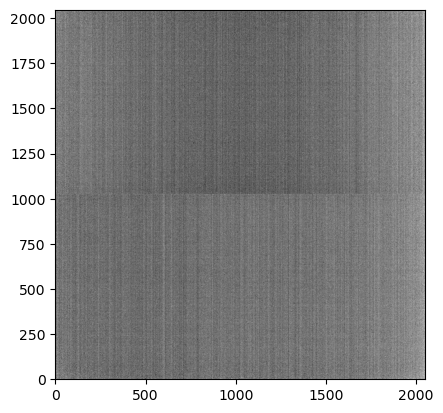

In [3]:
# Bias cube taken before the night, plus the four on-sky cubes taken with a zero exposure time
# (EXPTIME = 9.6e-6 s, they contain no starlight). Averaging 50 frames instead of 10 lowers the
# noise of the master bias, which otherwise limits the depth of the stacked images.
bias_frames = ['20240715/20240715T193453.0.pico.bias.fits',
               '20240715/20240715T213151.0.pico.object.fits',
               '20240715/20240715T213329.0.pico.object.fits',
               '20240715/20240715T213907.0.pico.object.fits',
               '20240715/20240715T214112.0.pico.object.fits']

# Create the master bias frame
master_bias = f_master_bias(bias_frames)
plt.imshow(master_bias, origin='lower', cmap='gray', vmin=98, vmax=107)

# Save the master bias frame to a new FITS file
fits.writeto('master_bias.fits', master_bias, overwrite=True)


Dark exposure time: 30.0 seconds


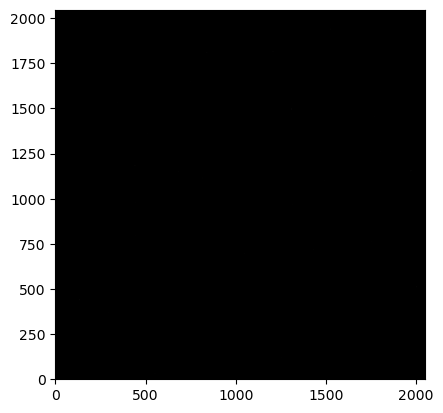

In [4]:
#Create master dark
dark_frames = '20240715/20240715T194008.0.pico.dark.fits'
master_bias = 'master_bias.fits'

master_dark = f_master_dark(dark_frames, master_bias)
plt.imshow(master_dark, origin='lower', cmap='gray')

fits.writeto('master_dark.fits', master_dark, overwrite=True)

Flat exposure time: 30.0 seconds


Flat frame levels: [37578. 37450. 37203. 37034. 31088. 28928. 28864. 29566. 25772. 22475.]


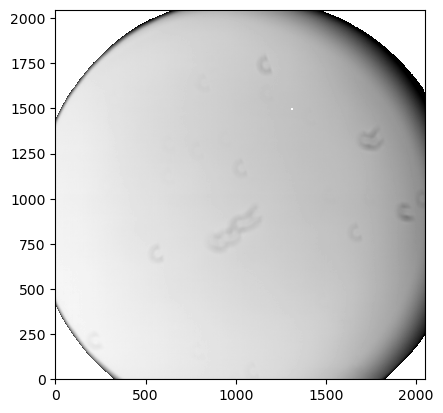

In [5]:
#Create master flat
flat_frames = '20240715/20240715T195154.0.pico.flat.fits'
master_bias = 'master_bias.fits'
master_dark = 'master_dark.fits'

master_flat = f_master_flat(flat_frames, master_bias, master_dark)

plt.imshow(master_flat, origin='lower', cmap='gray', vmin=0.6, vmax=1.1)

fits.writeto('master_flat.fits', master_flat, overwrite=True)


In [6]:
#Check the correction frames
master_flat = 'master_flat.fits'
bad_pixels = f_bad_pixel_mask(master_dark, master_flat)
fits.writeto('bad_pixels.fits', bad_pixels.astype(np.uint8), overwrite=True)

bias = fits.getdata(master_bias)
bias_cube = fits.getdata('20240715/20240715T193453.0.pico.bias.fits').astype(float)
read_noise = 1.4826 * np.median(np.abs(bias_cube[0] - bias_cube[1])) / np.sqrt(2)
dark = fits.getdata(master_dark)
flat = fits.getdata(master_flat)

print(f"Read noise per frame:  {read_noise:.2f} ADU")
print(f"Master bias:           median {np.median(bias):.2f} ADU, noise of the master ~ {read_noise / np.sqrt(50):.2f} ADU")
print(f"Master dark:           median {np.median(dark):.3f} ADU/s, {np.sum(np.abs(dark) > 10)} pixels above 10 ADU/s")
print(f"Master flat:           median of good pixels {np.nanmedian(flat):.3f}, NaN (vignetted) {np.mean(np.isnan(flat)) * 100:.1f} %")
print(f"Bad pixels:            {bad_pixels.mean() * 100:.2f} % of the detector")


Read noise per frame:  3.15 ADU
Master bias:           median 101.94 ADU, noise of the master ~ 0.44 ADU


Master dark:           median 0.089 ADU/s, 27197 pixels above 10 ADU/s
Master flat:           median of good pixels 1.006, NaN (vignetted) 7.6 %
Bad pixels:            8.15 % of the detector


# Science frames
The cubes with `EXPTIME = 9.6e-6 s` contain no starlight (they went into the master bias) and are skipped. Stacking happens after the correction, in `stacking and light curve.ipynb`: the old cell here summed the *raw* frames, so `20240715_stacked/` is not bias/dark/flat corrected and should not be used for photometry.


In [7]:
input_dir = "20240715"
output_dir = "20240715_reduced"
os.makedirs(output_dir, exist_ok=True)

science_files = sorted(glob.glob(f"{input_dir}/*.pico.object.fits"))

for science_file in science_files:
    if fits.getheader(science_file)['EXPTIME'] < 1e-3:
        print(f"Skipping {os.path.basename(science_file)}: zero exposure")
        continue

    science_frame, science_header = f_science_frame(
        science_file,
        master_bias,
        master_dark,
        master_flat,
        bad_pixels
    )

    base = os.path.basename(science_file)
    outname = base.replace(".fits", ".science.fits")
    outfile = os.path.join(output_dir, outname)

    fits.writeto(outfile, science_frame, science_header, overwrite=True)


Science exposure time: 30.0 seconds


Science exposure time: 30.0 seconds


Science exposure time: 30.0 seconds


Science exposure time: 30.0 seconds


Science exposure time: 30.0 seconds


Science exposure time: 30.0 seconds


... (11 outputs left out)

Science exposure time: 0.3 seconds


Science exposure time: 0.3 seconds


Science exposure time: 0.3 seconds


Science exposure time: 0.3 seconds
